# 01 · Generación de la base de datos ficticia

**Proyecto:** Evaluación mediante simulación de eventos discretos de estrategias de control semafórico ante una obstrucción en la Séptima Avenida (W29–W30), Manhattan.

**¿Qué hace este notebook?** Construye, paso a paso y de forma reproducible, la base de datos ficticia del proyecto: dos tablas relacionadas 1:N.

| Tabla | Una fila es… | Tamaño esperado |
|---|---|---|
| `intervalos` | un acceso de entrada durante 15 minutos | 7 días × 96 intervalos × 3 accesos = 2,016 filas |
| `vehiculos` | un carro que llega a la red | la suma de las llegadas (≈ 200,000 filas) |

**Idea central:** aquí solo generamos el tráfico que **llega**. Es el mismo para las tres estrategias de semáforos (A, B y C). Cuánto espera cada carro o hasta dónde crece la cola **no** se genera aquí: lo calculará la simulación en SimPy (notebook 02).

**Regla para decidir qué va en esta base:** si un valor depende de la estrategia de semáforos, es un resultado de la simulación, no un dato de entrada.

Reglas y diccionario aprobados: `docs/diseno_tecnico_borrador.md`, secciones 4 y 5.

## 1. Librerías y carpeta del proyecto

Importamos lo necesario y ubicamos la carpeta raíz del proyecto, para que las rutas funcionen igual si el notebook se abre desde `notebooks/` o desde la raíz.

- `numpy`: genera los números aleatorios (Poisson, uniforme, lognormal, Beta).
- `pandas`: arma y guarda las tablas.
- `matplotlib`: gráficas de verificación.
- `json`, `platform`, `datetime`: guardan el registro de la corrida (semilla, versiones y fecha).

In [1]:
import json
import platform
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Ubicar la raíz del proyecto: es la carpeta que contiene requirements.txt
RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
assert (RAIZ / "requirements.txt").exists(), "Abre Jupyter desde la carpeta del proyecto."

CARPETA_SALIDA = RAIZ / "datos" / "procesados"
CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)

print("Python:", platform.python_version())
print("numpy:", np.__version__, "| pandas:", pd.__version__)
print("Los archivos se guardarán en:", CARPETA_SALIDA.relative_to(RAIZ))

Python: 3.13.13
numpy: 2.5.4 | pandas: 3.1.1
Los archivos se guardarán en: datos/procesados


## 2. Semilla: por qué la base sale igual cada vez

Una computadora no genera azar "de verdad": usa una fórmula que produce números que **parecen** aleatorios. Esa fórmula arranca desde un número inicial llamado **semilla**.

- **Misma semilla → misma base**, exactamente igual, cada vez que se ejecute el notebook. Eso hace el trabajo **reproducible**: cualquier persona puede obtener los mismos datos.
- Si se cambia la semilla, cambian los datos, pero las **reglas** siguen siendo las mismas.

Usamos una sola semilla maestra y un único generador (`rng`). Todas las decisiones aleatorias salen de él, en el orden en que aparecen en este notebook. Por eso **no conviene ejecutar celdas sueltas o en otro orden**: para regenerar, usa *Kernel → Restart & Run All*.

In [2]:
SEMILLA = 20261112          # semilla maestra del proyecto (fecha en que se aprobaron las reglas)
rng = np.random.default_rng(SEMILLA)

# Demostración: con la misma semilla, los mismos números
demo_1 = np.random.default_rng(SEMILLA).poisson(30, size=5)
demo_2 = np.random.default_rng(SEMILLA).poisson(30, size=5)
print("Primera vez:", demo_1)
print("Segunda vez:", demo_2, "← idénticos")

Primera vez: [37 27 22 27 23]
Segunda vez: [37 27 22 27 23] ← idénticos


## 3. Supuestos del modelo (todos en un solo lugar)

Aquí quedan **todos los valores** que usamos para generar los datos. Tenerlos juntos sirve para:

1. revisarlos y defenderlos en el informe, y
2. cambiarlos fácilmente si después queremos hacer un análisis de sensibilidad (por ejemplo, probar la Séptima con 2× o 4× en vez de 3×).

| Supuesto | Valor | Origen |
|---|---|---|
| Forma del perfil horario | promedio real de W29, 22–24 abril 2019 | **dato histórico** (auditoría) |
| Séptima (33804) | 3 × perfil de W29 | supuesto: avenida de varios carriles |
| W30 (33803) | 0.9 × perfil de W29 | supuesto: calle similar a W29 |
| Fin de semana | 0.85 × perfil; pico 6:00–9:59 × 0.6 | supuesto |
| Variación entre días | factor lognormal, ±5 % | supuesto |
| Lluvia | 30 % de días con episodio de 2–5 h; ligera ×0.95, fuerte ×0.85 | supuesto |
| Evento en Madison Square Garden | 2 noches; llegada 18:00–19:45, salida 22:00–23:29 | supuesto con base en la ubicación |
| Proporción hacia el tramo | Séptima 0.85, W30 0.30, W29 0 | supuesto geométrico |
| Proporción de pesados | madrugada 12 %, día 8 %, noche 5 % | supuesto |

**Importante:** como son supuestos, los patrones que aparezcan en los datos **confirman que la generación funciona**, pero **no demuestran nada sobre el tráfico real** de Nueva York.

In [3]:
# --- Calendario ficticio: una semana completa, de lunes a domingo ---
FECHA_INICIO = pd.Timestamp("2026-03-02")      # lunes 2 de marzo de 2026
DIAS = 7
DURACION_INTERVALO_MIN = 15
INTERVALOS_POR_DIA = 24 * 60 // DURACION_INTERVALO_MIN   # 96

# --- Accesos de entrada a la red (IDs de segmento de NYC DOT) ---
ACCESOS = {
    33804: "Séptima Av. SB (entra a W30 desde el norte)",
    33803: "W30 EB (entra a W30 desde Eighth Av.)",
    33894: "W29 WB (entra a W29 desde Sixth Av.)",
}
# Cuántas veces el perfil de W29 tiene cada acceso
ESCALA_ACCESO = {33804: 3.0, 33803: 0.9, 33894: 1.0}

# --- Fin de semana ---
FACTOR_FIN_SEMANA = 0.85
FACTOR_PICO_AM_FIN_SEMANA = 0.6                 # aplica de 6:00 a 9:59

# --- Variación entre días (lognormal con media cercana a 1) ---
SIGMA_FACTOR_DIA = 0.05

# --- Lluvia ---
PROB_DIA_CON_LLUVIA = 0.30
DURACION_LLUVIA_H = (2, 5)                       # mínimo y máximo, en horas
PROB_LLUVIA_FUERTE = 0.30
FACTOR_LLUVIA = {"ninguna": 1.00, "ligera": 0.95, "fuerte": 0.85}

# --- Eventos en Madison Square Garden ---
NOCHES_CON_EVENTO = 2
VENTANA_LLEGADA_EVENTO = ("18:00", "19:45")     # inicio del primer y del último intervalo
VENTANA_SALIDA_EVENTO = ("22:00", "23:15")
FACTOR_LLEGADA_EVENTO = {33804: 1.25, 33803: 1.10, 33894: 1.00}
FACTOR_SALIDA_EVENTO = {33804: 1.40, 33803: 1.00, 33894: 1.00}

# --- Proporciones (media) y concentración de la distribución Beta ---
PROP_HACIA_TRAMO = {33804: 0.85, 33803: 0.30, 33894: 0.00}
PROP_PESADOS = {"madrugada": 0.12, "noche": 0.05, "otro": 0.08}
CONCENTRACION_BETA_TRAMO = 200
CONCENTRACION_BETA_PESADOS = 300
REPARTO_PESADOS = {"camion": 0.7, "bus": 0.3}    # cómo se dividen los pesados

print("Intervalos por día:", INTERVALOS_POR_DIA)
print("Filas esperadas en 'intervalos':", DIAS * INTERVALOS_POR_DIA * len(ACCESOS))

Intervalos por día: 96
Filas esperadas en 'intervalos': 2016


## 4. Perfil base de demanda (el único dato real que usamos)

En la auditoría de datos se calcularon los promedios por hora del acceso **33894 (W29)** a partir de conteos reales de NYC DOT (22–24 de abril de 2019, lunes a miércoles). Ese archivo está en `resultados/auditoria_historicos/perfil_horario_33894.csv`.

Usamos esa **forma** (dos picos: mañana y tarde) para los tres accesos, escalada según la tabla de supuestos.

**Unidad:** vehículos por hora (veh/h). Cada hora tiene 4 intervalos de 15 minutos con la misma tasa base.

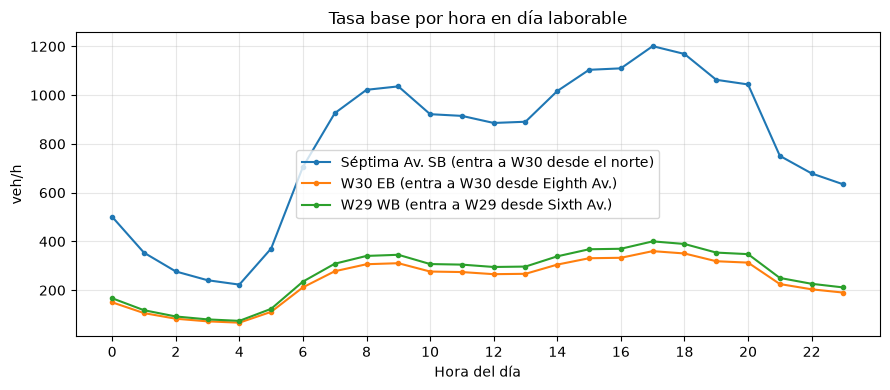

hora,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
33804,501.0,354.0,277.0,241.0,223.0,371.0,706.0,926.0,1022.0,1036.0,...,1017.0,1104.0,1110.0,1201.0,1169.0,1063.0,1044.0,751.0,679.0,634.0
33803,150.0,106.0,83.0,72.0,67.0,111.0,212.0,278.0,307.0,311.0,...,305.0,331.0,333.0,360.0,351.0,319.0,313.0,225.0,204.0,190.0
33894,167.0,118.0,92.0,80.0,74.0,124.0,235.0,309.0,341.0,345.0,...,339.0,368.0,370.0,400.0,390.0,354.0,348.0,250.0,226.0,211.0


In [4]:
perfil_w29 = pd.read_csv(RAIZ / "resultados" / "auditoria_historicos" / "perfil_horario_33894.csv")
perfil_w29 = perfil_w29.set_index("hora")["media_vph"]

# Tasa base por acceso y hora, en día laborable: perfil de W29 × escala del acceso
perfil_base = pd.DataFrame({acc: perfil_w29 * esc for acc, esc in ESCALA_ACCESO.items()})
perfil_base.index.name = "hora"

# Gráfica de verificación: ¿se ven los dos picos y la escala correcta?
ax = perfil_base.rename(columns=ACCESOS).plot(figsize=(9, 4), marker="o", ms=3)
ax.set(title="Tasa base por hora en día laborable", xlabel="Hora del día", ylabel="veh/h")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

perfil_base.round(0).T

**Lectura:** la Séptima tiene el triple de tráfico que W29 por el supuesto de escala. Los tres accesos comparten la misma forma: valle de madrugada, pico de mañana (8–9 h) y pico de tarde (17–18 h).

## 5. Esqueleto de la tabla `intervalos`

Primero armamos todas las combinaciones de **día × intervalo × acceso**, sin nada aleatorio todavía. Aquí se definen las variables de calendario:

- `fecha` (fecha) y `hora_inicio` (hora): ubican cada intervalo en el tiempo.
- `dia_semana` (**ordinal**): lun < mar < … < dom.
- `tipo_dia` (nominal): laborable o fin de semana.
- `periodo_dia` (nominal): madrugada (0–6 h), pico_am (7–9 h), valle (10–15 h), pico_pm (16–19 h), noche (20–23 h).

In [5]:
NOMBRES_DIA = ["lun", "mar", "mie", "jue", "vie", "sab", "dom"]

def periodo_del_dia(hora):
    # Clasifica una hora (0–23) en su franja del día
    if hora <= 6:
        return "madrugada"
    if hora <= 9:
        return "pico_am"
    if hora <= 15:
        return "valle"
    if hora <= 19:
        return "pico_pm"
    return "noche"

filas = []
for d in range(DIAS):
    fecha = FECHA_INICIO + pd.Timedelta(days=d)
    for i in range(INTERVALOS_POR_DIA):
        minuto = i * DURACION_INTERVALO_MIN
        hora = minuto // 60
        for acceso in ACCESOS:
            filas.append({
                "fecha": fecha.date(),
                "dia_semana": NOMBRES_DIA[fecha.dayofweek],
                "tipo_dia": "fin_semana" if fecha.dayofweek >= 5 else "laborable",
                "hora_inicio": f"{hora:02d}:{minuto % 60:02d}",
                "hora": hora,                      # columna auxiliar, se elimina al final
                "periodo_dia": periodo_del_dia(hora),
                "acceso_id": acceso,
            })

intervalos = pd.DataFrame(filas)
intervalos.insert(0, "intervalo_id", np.arange(1, len(intervalos) + 1))
intervalos["dia_semana"] = pd.Categorical(intervalos["dia_semana"], categories=NOMBRES_DIA, ordered=True)

print("Filas:", len(intervalos))
intervalos.head(6)

Filas: 2016


/var/folders/hl/0y2g2df5401bwym2q43r1x1m0000gn/T/ipykernel_5753/159160759.py:24: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "dia_semana": NOMBRES_DIA[fecha.dayofweek],
/var/folders/hl/0y2g2df5401bwym2q43r1x1m0000gn/T/ipykernel_5753/159160759.py:25: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  "tipo_dia": "fin_semana" if fecha.dayofweek >= 5 else "laborable",


,intervalo_id,fecha,dia_semana,tipo_dia,hora_inicio,hora,periodo_dia,acceso_id
0,1,2026-03-02,lun,laborable,00:00,0,madrugada,33804
1,2,2026-03-02,lun,laborable,00:00,0,madrugada,33803
2,3,2026-03-02,lun,laborable,00:00,0,madrugada,33894
3,4,2026-03-02,lun,laborable,00:15,0,madrugada,33804
4,5,2026-03-02,lun,laborable,00:15,0,madrugada,33803
5,6,2026-03-02,lun,laborable,00:15,0,madrugada,33894


## 6. Lluvia y eventos en Madison Square Garden

**Lluvia.** Cada día tiene 30 % de probabilidad de tener un episodio de lluvia. Si lo tiene, se sortean la hora de inicio, la duración (2 a 5 horas) y la intensidad (ligera 70 %, fuerte 30 %).

*Regla de coherencia:* la lluvia se decide **por día y hora**, no por acceso. Así llueve igual en las tres calles al mismo tiempo, como en la realidad.

**Eventos.** Madison Square Garden está a un par de cuadras al norte (Séptima–Octava Av., W31–W33). Se eligen al azar 2 noches con evento, con dos ventanas de tráfico extra: la llegada del público (18:00–19:45) y la salida (22:00–23:29).

In [6]:
# --- Lluvia: un posible episodio por día ---
lluvia_por_dia_hora = {}           # (fecha, hora) -> intensidad
for d in range(DIAS):
    fecha = (FECHA_INICIO + pd.Timedelta(days=d)).date()
    for h in range(24):
        lluvia_por_dia_hora[(fecha, h)] = "ninguna"
    if rng.random() < PROB_DIA_CON_LLUVIA:
        inicio = int(rng.integers(0, 24))
        duracion = int(rng.integers(DURACION_LLUVIA_H[0], DURACION_LLUVIA_H[1] + 1))
        intensidad = "fuerte" if rng.random() < PROB_LLUVIA_FUERTE else "ligera"
        for h in range(inicio, min(inicio + duracion, 24)):   # el episodio no pasa al día siguiente
            lluvia_por_dia_hora[(fecha, h)] = intensidad
        print(f"{fecha}: lluvia {intensidad} de {inicio}:00 a {min(inicio + duracion, 24)}:00")

intervalos["lluvia"] = [lluvia_por_dia_hora[(f, h)] for f, h in zip(intervalos["fecha"], intervalos["hora"])]
intervalos["lluvia"] = pd.Categorical(intervalos["lluvia"], categories=["ninguna", "ligera", "fuerte"], ordered=True)

# --- Eventos: 2 noches al azar ---
dias_evento = sorted(rng.choice(DIAS, size=NOCHES_CON_EVENTO, replace=False))
fechas_evento = [(FECHA_INICIO + pd.Timedelta(days=int(d))).date() for d in dias_evento]
print("Noches con evento:", [f"{f} ({NOMBRES_DIA[pd.Timestamp(f).dayofweek]})" for f in fechas_evento])

en_dia_evento = intervalos["fecha"].isin(fechas_evento)
en_llegada = intervalos["hora_inicio"].between(*VENTANA_LLEGADA_EVENTO)
en_salida = intervalos["hora_inicio"].between(*VENTANA_SALIDA_EVENTO)
intervalos["fase_evento"] = np.select(
    [en_dia_evento & en_llegada, en_dia_evento & en_salida], ["llegada", "salida"], default="ninguna"
)                                   # columna auxiliar, se elimina al final
intervalos["evento_msg"] = np.where(intervalos["fase_evento"] != "ninguna", "sí", "no")

intervalos.groupby("evento_msg", observed=True).size().rename("intervalos")

2026-03-03: lluvia ligera de 23:00 a 24:00
2026-03-04: lluvia ligera de 2:00 a 5:00
2026-03-06: lluvia fuerte de 16:00 a 19:00
2026-03-08: lluvia ligera de 19:00 a 22:00
Noches con evento: ['2026-03-02 (lun)', '2026-03-03 (mar)']


/var/folders/hl/0y2g2df5401bwym2q43r1x1m0000gn/T/ipykernel_5753/3580802314.py:21: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  print("Noches con evento:", [f"{f} ({NOMBRES_DIA[pd.Timestamp(f).dayofweek]})" for f in fechas_evento])


evento_msg
no    1932
sí      84
Name: intervalos, dtype: int64

## 7. La tasa de llegada λ de cada intervalo

Ahora calculamos la tasa media esperada, **λ** (lambda, en veh/h), multiplicando el perfil base por cada factor:

$$\lambda = \lambda_{base}(\text{acceso}, \text{hora}) \times f_{\text{fin de semana}} \times f_{\text{día}} \times f_{\text{lluvia}} \times f_{\text{evento}}$$

**Ejemplo a mano (ilustrativo):** Séptima a las 17:00 de un laborable, sin lluvia ni evento, con factor del día = 1.02:

λ = 1,201 × 1 × 1.02 × 1 × 1 ≈ **1,225 veh/h**

**El factor del día.** En la vida real, unos días tienen un poco más de tráfico que otros en todas las horas. Lo representamos con un número cercano a 1 para cada combinación de día y acceso, sacado de una distribución **lognormal**. La usamos porque siempre da valores positivos, alrededor de 1, con una variación de ±5 %. Sin este factor, todos los lunes a viernes serían casi idénticos.

In [7]:
# Tasa base según acceso y hora
intervalos["tasa_base"] = [perfil_base.loc[h, a] for h, a in zip(intervalos["hora"], intervalos["acceso_id"])]

# Factor de fin de semana (y pico de mañana más bajo)
es_fds = intervalos["tipo_dia"] == "fin_semana"
f_fds = np.where(es_fds, FACTOR_FIN_SEMANA, 1.0)
f_fds = np.where(es_fds & intervalos["hora"].between(6, 9), f_fds * FACTOR_PICO_AM_FIN_SEMANA, f_fds)

# Factor del día: uno por (fecha, acceso), lognormal con media cercana a 1
claves_dia = intervalos[["fecha", "acceso_id"]].drop_duplicates().reset_index(drop=True)
claves_dia["f_dia"] = rng.lognormal(mean=0.0, sigma=SIGMA_FACTOR_DIA, size=len(claves_dia))
intervalos = intervalos.merge(claves_dia, on=["fecha", "acceso_id"], how="left")

# Factores de lluvia y de evento
f_lluvia = intervalos["lluvia"].astype(str).map(FACTOR_LLUVIA)
f_evento = np.select(
    [intervalos["fase_evento"] == "llegada", intervalos["fase_evento"] == "salida"],
    [intervalos["acceso_id"].map(FACTOR_LLEGADA_EVENTO), intervalos["acceso_id"].map(FACTOR_SALIDA_EVENTO)],
    default=1.0,
)

intervalos["tasa_llegada_vph"] = (intervalos["tasa_base"] * f_fds * intervalos["f_dia"] * f_lluvia * f_evento).round(2)

print("Factores del día (deben estar cerca de 1):")
print(claves_dia["f_dia"].describe().round(3).to_string())

Factores del día (deben estar cerca de 1):
count    21.000
mean      1.007
std       0.040
min       0.937
25%       0.992
50%       0.999
75%       1.017
max       1.088


## 8. De la tasa al conteo: la distribución de Poisson

**La idea en palabras.** En 15 minutos hay muchísimos conductores que *podrían* llegar a la esquina, y cada uno tiene una probabilidad pequeña e independiente de hacerlo justo en ese intervalo. Cuando se suman muchos eventos raros e independientes, el total sigue una **distribución de Poisson**.

**El promedio esperado en el intervalo:**

$$\mu = \lambda \times \Delta t, \qquad \Delta t = \frac{15}{60} = 0.25 \text{ h}$$

Ejemplo: con λ = 1,200 veh/h, μ = 1,200 × 0.25 = **300 carros**.

**La fórmula** da la probabilidad de que lleguen exactamente $k$ carros:

$$P(N = k) = \frac{e^{-\mu}\,\mu^{k}}{k!}$$

**Propiedad clave:** la media y la varianza son iguales (μ), así que la desviación estándar es √μ. Con μ = 300 lo normal es ver entre unos 265 y 335 carros, no exactamente 300.

**Cuándo NO sirve:** si los carros dejan de ser independientes, por ejemplo cuando un semáforo los suelta en grupo. Por eso Poisson se usa solo en las **entradas externas**. El tramo interno W30→W29 lo calcula la simulación.

In [8]:
mu = intervalos["tasa_llegada_vph"] * DURACION_INTERVALO_MIN / 60   # promedio esperado en 15 min
intervalos["llegadas"] = rng.poisson(mu)

# Ejemplo concreto: los primeros intervalos de la Séptima a las 17:00
ejemplo = intervalos[(intervalos["acceso_id"] == 33804) & (intervalos["hora_inicio"] == "17:00")]
ejemplo[["fecha", "dia_semana", "tasa_llegada_vph", "llegadas"]].assign(mu=(ejemplo["tasa_llegada_vph"] / 4).round(1))

,fecha,dia_semana,tasa_llegada_vph,llegadas,mu
204,2026-03-02,lun,1214.15,311,303.5
492,2026-03-03,mar,1190.82,274,297.7
780,2026-03-04,mie,1299.58,350,324.9
1068,2026-03-05,jue,1142.61,256,285.7
1356,2026-03-06,vie,1016.08,257,254.0
1644,2026-03-07,sab,1032.35,240,258.1
1932,2026-03-08,dom,1019.60,262,254.9


**Lectura:** en cada día, `llegadas` queda cerca de μ (la tasa dividida entre 4), pero nunca es exactamente igual. Esa variación es la aleatoriedad de Poisson, y es la que después forma colas en la simulación.

## 9. Proporciones por intervalo (distribución Beta)

Dos proporciones describen la composición del tráfico de cada intervalo:

- `prop_hacia_tramo`: qué fracción de los que llegan **debe entrar al tramo W30–W29**. Séptima ≈ 0.85 (casi todos siguen recto), W30 ≈ 0.30 (solo los que giran a la derecha hacia la Séptima). W29 = 0, porque entra **después** del tramo.
- `prop_pesados`: fracción de camiones y buses. Es más alta de madrugada, por las entregas.

Para que varíen un poco entre intervalos, usamos la distribución **Beta**: siempre da valores entre 0 y 1, centrados en la media que elegimos. La "concentración" controla cuánto se aleja de la media; con 200–300 la variación es pequeña, de unos ±2 a 3 puntos porcentuales.

In [9]:
def beta_con_media(media, concentracion, n):
    # Sortea n proporciones Beta con la media indicada; si la media es 0, todas valen 0
    media = np.asarray(media, dtype=float)
    resultado = np.zeros(n)
    hay = media > 0
    a = media[hay] * concentracion
    b = (1 - media[hay]) * concentracion
    resultado[hay] = rng.beta(a, b)
    return resultado

media_tramo = intervalos["acceso_id"].map(PROP_HACIA_TRAMO).to_numpy()
intervalos["prop_hacia_tramo"] = beta_con_media(media_tramo, CONCENTRACION_BETA_TRAMO, len(intervalos)).round(4)

media_pesados = intervalos["periodo_dia"].map(lambda p: PROP_PESADOS.get(p, PROP_PESADOS["otro"])).to_numpy()
intervalos["prop_pesados"] = beta_con_media(media_pesados, CONCENTRACION_BETA_PESADOS, len(intervalos)).round(4)

intervalos.groupby("acceso_id")[["prop_hacia_tramo", "prop_pesados"]].agg(["mean", "min", "max"]).round(3)

prop_hacia_tramo               prop_pesados              
                      mean    min    max         mean    min    max
acceso_id                                                          
33803                 0.30  0.192  0.391        0.087  0.027  0.184
33804                 0.85  0.771  0.916        0.085  0.020  0.168
33894                 0.00  0.000  0.000        0.087  0.020  0.168

## 10. La tabla `vehiculos`: un carro por fila

Cada intervalo con `llegadas = N` produce **N filas** en `vehiculos`. Esa es la relación **1:N**. Para cada carro decidimos:

1. **`segundo_llegada`**: un instante al azar entre 0 y 900 s, con distribución **uniforme**. No es un supuesto extra: es una propiedad del proceso de Poisson. Si sabemos que llegaron N carros en un intervalo, sus instantes se reparten de forma uniforme dentro de él.
2. **`tipo_vehiculo`**: auto con probabilidad 1 − p; camión con 0.7p; bus con 0.3p, donde p = `prop_pesados` de su intervalo.
3. **`movimiento`**: `entra_tramo` con probabilidad `prop_hacia_tramo`; si no, `otro`.

Así cada carro hereda las características de su intervalo.

In [10]:
# Repetir los datos de cada intervalo tantas veces como carros llegaron
n_por_intervalo = intervalos["llegadas"].to_numpy()
idx = np.repeat(np.arange(len(intervalos)), n_por_intervalo)
total = len(idx)

vehiculos = pd.DataFrame({"intervalo_id": intervalos["intervalo_id"].to_numpy()[idx]})

# 1) Instante de llegada dentro del intervalo (uniforme en [0, 900) s)
vehiculos["segundo_llegada"] = rng.uniform(0, DURACION_INTERVALO_MIN * 60, size=total).round(2)

# 2) Tipo de vehículo según la proporción de pesados del intervalo
p_pes = intervalos["prop_pesados"].to_numpy()[idx]
u = rng.random(total)
vehiculos["tipo_vehiculo"] = np.select(
    [u < p_pes * REPARTO_PESADOS["camion"], u < p_pes], ["camion", "bus"], default="auto"
)

# 3) Movimiento según la proporción que entra al tramo
p_tramo = intervalos["prop_hacia_tramo"].to_numpy()[idx]
vehiculos["movimiento"] = np.where(rng.random(total) < p_tramo, "entra_tramo", "otro")

# Ordenar por intervalo y segundo, y asignar la clave del vehículo
vehiculos = vehiculos.sort_values(["intervalo_id", "segundo_llegada"], kind="stable").reset_index(drop=True)
vehiculos.insert(0, "vehiculo_id", np.arange(1, total + 1))

# 4) Momento exacto: fecha + hora de inicio del intervalo + segundos
inicio_intervalo = pd.to_datetime(intervalos["fecha"].astype(str) + " " + intervalos["hora_inicio"])
inicio_por_id = pd.Series(inicio_intervalo.to_numpy(), index=intervalos["intervalo_id"])
vehiculos["fecha_hora_llegada"] = (
    vehiculos["intervalo_id"].map(inicio_por_id) + pd.to_timedelta(vehiculos["segundo_llegada"], unit="s")
)
vehiculos = vehiculos[["vehiculo_id", "intervalo_id", "segundo_llegada", "fecha_hora_llegada", "tipo_vehiculo", "movimiento"]]

print(f"Vehículos generados: {total:,}")
vehiculos.head(8)

Vehículos generados: 206,888


,vehiculo_id,intervalo_id,segundo_llegada,fecha_hora_llegada,tipo_vehiculo,movimiento
0,1,1,0.45,2026-03-02 00:00:00.450,auto,otro
1,2,1,7.54,2026-03-02 00:00:07.540,auto,entra_tramo
2,3,1,18.23,2026-03-02 00:00:18.230,auto,entra_tramo
3,4,1,18.60,2026-03-02 00:00:18.600,auto,entra_tramo
4,5,1,25.33,2026-03-02 00:00:25.330,auto,entra_tramo
5,6,1,32.56,2026-03-02 00:00:32.560,auto,entra_tramo
6,7,1,37.97,2026-03-02 00:00:37.970,auto,entra_tramo
7,8,1,43.53,2026-03-02 00:00:43.530,auto,entra_tramo


## 11. Validaciones de integridad

Antes de guardar, comprobamos con `assert` que la base cumple las **reglas de negocio** del diccionario. Si alguna falla, el notebook se detiene con un mensaje que dice cuál, y así no se guarda una base con errores.

| Regla | Por qué importa |
|---|---|
| 2,016 filas e `intervalo_id` único | tamaño y llave correctos |
| `llegadas` = número de vehículos de ese intervalo | la relación 1:N es consistente |
| cada `intervalo_id` de `vehiculos` existe en `intervalos` | no hay carros "huérfanos" |
| proporciones en [0, 1]; conteos y tasas ≥ 0 | valores posibles |
| `segundo_llegada` < 900 | el carro cae dentro de su intervalo |
| W29 nunca entra al tramo | coherencia geométrica |
| lluvia igual en los 3 accesos a la misma hora | coherencia física |
| sin valores nulos | base completa |

In [11]:
conteo_real = vehiculos.groupby("intervalo_id").size().reindex(intervalos["intervalo_id"], fill_value=0)

assert len(intervalos) == DIAS * INTERVALOS_POR_DIA * len(ACCESOS), "Cantidad de intervalos incorrecta"
assert intervalos["intervalo_id"].is_unique and vehiculos["vehiculo_id"].is_unique, "Llaves repetidas"
assert (conteo_real.to_numpy() == intervalos["llegadas"].to_numpy()).all(), "llegadas ≠ vehículos del intervalo"
assert vehiculos["intervalo_id"].isin(intervalos["intervalo_id"]).all(), "Hay vehículos sin intervalo"
assert intervalos["prop_hacia_tramo"].between(0, 1).all() and intervalos["prop_pesados"].between(0, 1).all()
assert (intervalos["llegadas"] >= 0).all() and (intervalos["tasa_llegada_vph"] >= 0).all()
assert vehiculos["segundo_llegada"].between(0, 900, inclusive="left").all(), "Llegada fuera del intervalo"
assert (intervalos.loc[intervalos["acceso_id"] == 33894, "prop_hacia_tramo"] == 0).all()
assert intervalos.groupby(["fecha", "hora_inicio"], observed=True)["lluvia"].nunique().max() == 1, "Lluvia incoherente"
assert not vehiculos.loc[vehiculos["movimiento"] == "entra_tramo"].merge(
    intervalos.loc[intervalos["acceso_id"] == 33894, ["intervalo_id"]]).shape[0], "Un carro de W29 entra al tramo"
assert intervalos.notna().all().all() and vehiculos.notna().all().all(), "Hay valores nulos"

print("✓ Todas las validaciones pasaron.")

✓ Todas las validaciones pasaron.


## 12. Verificación estadística: ¿la generación se comporta como esperábamos?

Dos comprobaciones rápidas, solo para verificar que el código hace lo que dicen las reglas. El análisis exploratorio completo va en el notebook de la fase 2.

1. **Promedio por hora vs. tasa esperada:** el promedio de `llegadas` por hora debe seguir la curva de λ.
2. **Propiedad de Poisson:** en los intervalos de tasa parecida, la varianza de `llegadas` debe ser **un poco mayor** que la media. Pura Poisson daría varianza = media, pero el factor del día y el clima agregan variación real entre días. Ese exceso se llama **sobredispersión** y es esperable.

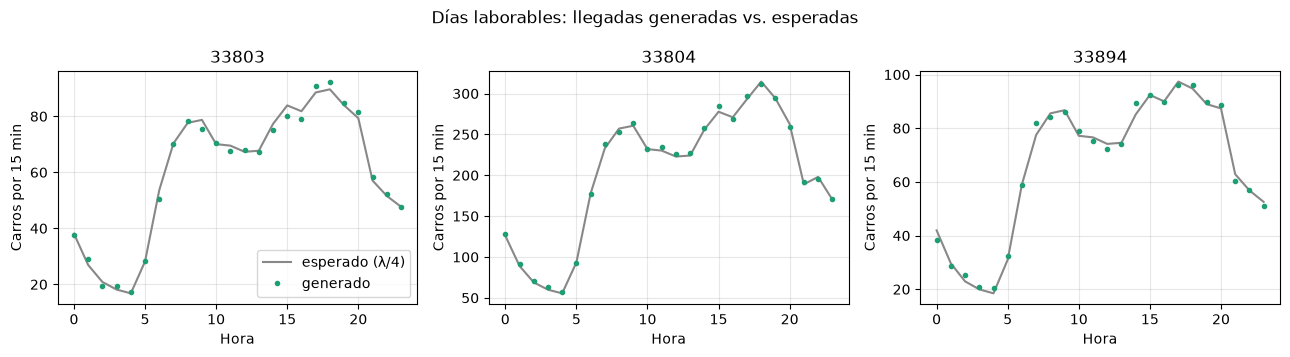

,mean,var,varianza/media
acceso_id,,,
33803,90.8,99.6,1.1
33804,297.2,1055.1,3.6
33894,96.0,106.2,1.1


In [12]:
lab = intervalos[intervalos["tipo_dia"] == "laborable"]
comparacion = lab.groupby(["acceso_id", "hora"]).agg(
    llegadas_promedio=("llegadas", "mean"), esperado=("tasa_llegada_vph", lambda s: s.mean() / 4)
).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
for ax, (acc, df) in zip(axes, comparacion.groupby("acceso_id")):
    ax.plot(df["hora"], df["esperado"], label="esperado (λ/4)", color="#888")
    ax.plot(df["hora"], df["llegadas_promedio"], "o", ms=3, label="generado", color="#1D9E75")
    ax.set(title=f"{acc}", xlabel="Hora", ylabel="Carros por 15 min")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.suptitle("Días laborables: llegadas generadas vs. esperadas")
plt.tight_layout()
plt.show()

# Índice de dispersión (varianza / media) por acceso en la hora pico de la tarde, días laborables
pico = lab[lab["hora"] == 17].groupby("acceso_id")["llegadas"].agg(["mean", "var"])
pico["varianza/media"] = (pico["var"] / pico["mean"]).round(2)
pico.round(1)

**Lectura:**
- Los puntos verdes caen sobre la curva esperada en los tres accesos: la generación sigue el perfil.
- El cociente varianza/media queda por encima de 1 (sobredispersión) porque mezcla días con distintos factores (la variación diaria y, en algunos días, la lluvia). Es lo esperado según las reglas y se parece más al tráfico real que una Poisson pura. Con solo 5 días laborables por hora, este cociente es aproximado.

## 13. Tabulación final (al estilo de la Figura 21 de la tesis)

Dejamos las tablas con **solo las variables del diccionario aprobado** (13 + 6), en el orden del diccionario, y eliminamos las columnas auxiliares de cálculo (`hora`, `tasa_base`, `f_dia`, `fase_evento`).

Como en la Figura 21, revisamos la estructura: nombre, tipo de dato, cantidad de valores y rango de cada variable.

In [13]:
COLUMNAS_INTERVALOS = [
    "intervalo_id", "fecha", "dia_semana", "tipo_dia", "hora_inicio", "periodo_dia", "acceso_id",
    "lluvia", "evento_msg", "tasa_llegada_vph", "llegadas", "prop_hacia_tramo", "prop_pesados",
]
intervalos = intervalos[COLUMNAS_INTERVALOS]

def ficha(df):
    # Resumen de estructura: tipo, no nulos, valores distintos y rango o categorías
    filas = []
    for c in df.columns:
        s = df[c]
        if pd.api.types.is_numeric_dtype(s) and c not in ("intervalo_id", "vehiculo_id", "acceso_id"):
            rango = f"{s.min():,.2f} – {s.max():,.2f}"
        else:
            valores = s.astype(str).unique()
            rango = ", ".join(valores[:5]) + (" …" if len(valores) > 5 else "")
        filas.append({"variable": c, "tipo_pandas": str(s.dtype), "no_nulos": s.notna().sum(),
                      "distintos": s.nunique(), "rango_o_categorias": rango})
    return pd.DataFrame(filas)

print("Tabla 'intervalos':", intervalos.shape)
ficha(intervalos)

Tabla 'intervalos': (2016, 13)


,variable,tipo_pandas,no_nulos,distintos,rango_o_categorias
0,intervalo_id,int64,2016,2016,"1, 2, 3, 4, 5 …"
1,fecha,object,2016,7,"2026-03-02, 2026-03-03, 2026-03-04, 2026-03-05..."
2,dia_semana,category,2016,7,"lun, mar, mie, jue, vie …"
3,tipo_dia,str,2016,2,"laborable, fin_semana"
4,hora_inicio,str,2016,96,"00:00, 00:15, 00:30, 00:45, 01:00 …"
5,periodo_dia,str,2016,5,"madrugada, pico_am, valle, pico_pm, noche"
6,acceso_id,int64,2016,3,"33804, 33803, 33894"
7,lluvia,category,2016,3,"ninguna, ligera, fuerte"
8,evento_msg,str,2016,2,"no, sí"
9,tasa_llegada_vph,float64,2016,506,"56.82 – 1,477.25"


In [14]:
print("Tabla 'vehiculos':", vehiculos.shape)
ficha(vehiculos)

Tabla 'vehiculos': (206888, 6)


,variable,tipo_pandas,no_nulos,distintos,rango_o_categorias
0,vehiculo_id,int64,206888,206888,"1, 2, 3, 4, 5 …"
1,intervalo_id,int64,206888,2016,"1, 2, 3, 4, 5 …"
2,segundo_llegada,float64,206888,80898,0.00 – 899.99
3,fecha_hora_llegada,datetime64[ns],206888,206479,"2026-03-02 00:00:00.450, 2026-03-02 00:00:07.5..."
4,tipo_vehiculo,str,206888,3,"auto, camion, bus"
5,movimiento,str,206888,2,"otro, entra_tramo"


In [15]:
# Vista de las primeras filas de la tabla principal, como en la tabulación de la tesis
intervalos.head(10)

,intervalo_id,fecha,dia_semana,tipo_dia,hora_inicio,periodo_dia,acceso_id,lluvia,evento_msg,tasa_llegada_vph,llegadas,prop_hacia_tramo,prop_pesados
0,1,2026-03-02,lun,laborable,00:00,madrugada,33804,ninguna,no,506.49,123,0.8390,0.1136
1,2,2026-03-02,lun,laborable,00:00,madrugada,33803,ninguna,no,149.89,36,0.2812,0.1169
2,3,2026-03-02,lun,laborable,00:00,madrugada,33894,ninguna,no,156.40,43,0.0000,0.0790
3,4,2026-03-02,lun,laborable,00:15,madrugada,33804,ninguna,no,506.49,145,0.8616,0.0794
4,5,2026-03-02,lun,laborable,00:15,madrugada,33803,ninguna,no,149.89,41,0.3122,0.1327
5,6,2026-03-02,lun,laborable,00:15,madrugada,33894,ninguna,no,156.40,31,0.0000,0.1479
6,7,2026-03-02,lun,laborable,00:30,madrugada,33804,ninguna,no,506.49,122,0.8571,0.1189
7,8,2026-03-02,lun,laborable,00:30,madrugada,33803,ninguna,no,149.89,48,0.3371,0.1410
8,9,2026-03-02,lun,laborable,00:30,madrugada,33894,ninguna,no,156.40,31,0.0000,0.1107
9,10,2026-03-02,lun,laborable,00:45,madrugada,33804,ninguna,no,506.49,135,0.8064,0.0886


## 14. Guardar la base y el registro de la corrida

Guardamos:

- `datos/procesados/intervalos.csv` y `datos/procesados/vehiculos.csv`: las dos tablas.
- `datos/procesados/manifiesto_generacion.json`: la semilla, las versiones de Python y librerías, la fecha y los totales. Sirve para comprobar después que una base corresponde a esta corrida.

Los CSV quedan solo en tu computadora (`datos/procesados/` está excluida de Git), pero el notebook permite volver a generarlos idénticos con la misma semilla.

In [16]:
intervalos.to_csv(CARPETA_SALIDA / "intervalos.csv", index=False)
vehiculos.to_csv(CARPETA_SALIDA / "vehiculos.csv", index=False)

manifiesto = {
    "generado": datetime.now().isoformat(timespec="seconds"),
    "semilla": SEMILLA,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "filas_intervalos": int(len(intervalos)),
    "filas_vehiculos": int(len(vehiculos)),
    "noches_con_evento": [str(f) for f in fechas_evento],
    "dias_con_lluvia": sorted({str(f) for (f, h), v in lluvia_por_dia_hora.items() if v != "ninguna"}),
    "supuestos": {
        "escala_acceso": {str(k): v for k, v in ESCALA_ACCESO.items()},
        "factor_fin_semana": FACTOR_FIN_SEMANA,
        "factor_lluvia": FACTOR_LLUVIA,
        "prop_hacia_tramo": {str(k): v for k, v in PROP_HACIA_TRAMO.items()},
        "prop_pesados": PROP_PESADOS,
    },
}
(CARPETA_SALIDA / "manifiesto_generacion.json").write_text(json.dumps(manifiesto, ensure_ascii=False, indent=2))

for archivo in ["intervalos.csv", "vehiculos.csv", "manifiesto_generacion.json"]:
    tam = (CARPETA_SALIDA / archivo).stat().st_size / 1e6
    print(f"{archivo:28s} {tam:6.2f} MB")

intervalos.csv                 0.17 MB
vehiculos.csv                 11.55 MB
manifiesto_generacion.json     0.00 MB


## 15. Conclusión y límites

**Qué obtuvimos:**
- Una base ficticia **reproducible** (semilla 20261112) con dos tablas relacionadas 1:N: 2,016 intervalos y un vehículo por fila.
- 19 variables de todos los tipos que pide la guía: identificadores, fecha y hora, nominales, ordinales (`dia_semana`, `lluvia`), discretas (`llegadas`) y continuas (`tasa_llegada_vph`, proporciones, `segundo_llegada`).
- Dependencias explícitas: hora → demanda, fin de semana → demanda, lluvia → demanda, evento → demanda, periodo → pesados.
- Todas las validaciones de integridad pasaron.

**Límites que hay que declarar en el informe:**
- La forma del perfil viene de 3 días de 2019, anteriores a la pandemia, y de un solo acceso.
- Las escalas de la Séptima (3×) y de W30 (0.9×), los efectos de lluvia y evento y las proporciones son **supuestos**, no mediciones.
- Las llegadas son Poisson **solo en las entradas externas**. En el tramo interno los carros llegan en grupos, y eso lo resolverá SimPy.
- Como los datos son ficticios, los patrones que se encuentren en el análisis exploratorio confirman las reglas de generación, no el comportamiento real de Nueva York.

**Siguiente paso:** el notebook de la fase 2, con el análisis exploratorio al estilo de las Figuras 21 a 33 de la tesis y gráficas de distribución para al menos tres variables.